    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]

The Upper Bound
Upper bound: 8.76371200713939

Updated study hours for the last student: 8.76371200713939

I chose to cap the outlier because it lets us retain the student instead of deleting the entire row.

Invalid study hours:
74   -0.23949
Name: study_hours, dtype: float64

Median Hour: 4.855979756

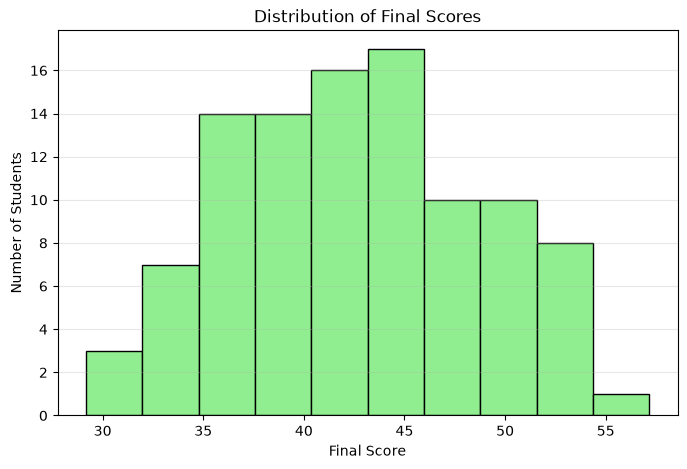


Obesration: The histogram shows am approximately bell shaped and unimodal distribution. Most students' scores are concentrated between approximately 35 and 50, with the highest being around 42 to 45. The standard deviation that was calculated ealier tells thers is moderate variation in students' final scores which can be seen in the graph and there are no obvious extreme outliers.


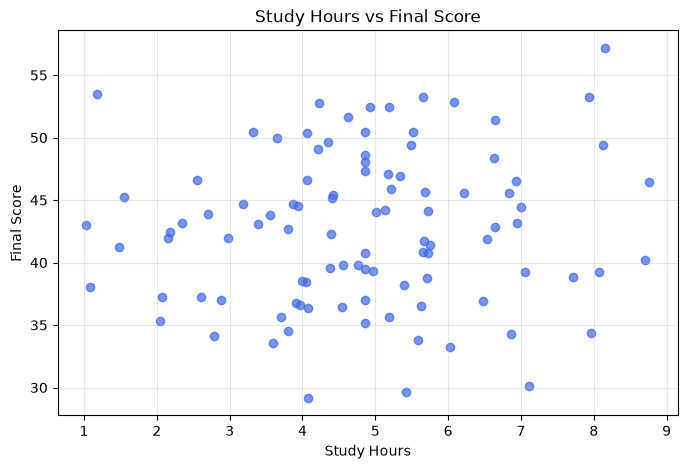


Observation: The scatter plot of final score and study hours show no uppward or downward line correlation and have weak relation to each other. This suggests that study hours alone do not explain the differences in students' final scores. The other factors, which are attendance, previous mark, and random variation also influenced the final score.

Part D

Pearson Correlation Coefficient: 0.09

Since the correlation coefficient is a very small or close to zero positive linear correlation, it doesn't guarantee a student will have a specific score based on their study hour.

A potential confounding variable is student motivation. Highly motivated students may study longer and also perform better because they prepare more effectively, practice regularly, or use better learning strategies.

Part E

Student feature vector: [ 4.85597976 70.84629258 75.36681041]
Weight vector: [0.5 0.2 0.4]
Bias: 5
Predicted score: 51.743972556408536
Actual final score: 35.17898895329447

The weight vector (f

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
 
 
np.random.seed(42) 
 
 
n = 100 
study_hours = np.random.normal(5, 2, n) 
attendance = np.random.normal(85, 10, n) 
previous_mark = np.random.normal(70, 15, n) 
 
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n) 
 
df = pd.DataFrame({ 
    'study_hours': study_hours, 
    'attendance': attendance, 
    'previous_mark': previous_mark, 
    'final_score': final_score 
}) 
 
 
df.loc[0:5, 'study_hours'] = np.nan  # Missing values 
df.loc[99, 'study_hours'] = 50       # Outlier 
df.loc[98, 'attendance'] = -10       # Impossible value 

print(df) 
df.to_csv('student_data.csv', index=False)

# CLEANING STUDY_HOURS
# calculate IQR of study_hours
Q1 = df["study_hours"].quantile(0.25)
Q3 = df["study_hours"].quantile(0.75)

print("\nThe Upper Bound")
IQR = Q3 - Q1
upper_bound = Q3 + 1.5*IQR
print("Upper bound:", upper_bound)

df.loc[99, 'study_hours'] = upper_bound

print("\nUpdated study hours for the last student:", df.loc[99, 'study_hours'])

print("\nI chose to cap the outlier because it lets us retain the student instead of deleting the entire row.")

invalid_hours = df["study_hours"] < 0
print("\nInvalid study hours:")
print(df.loc[invalid_hours, "study_hours"])

df.loc[invalid_hours, "study_hours"] = np.nan

# calculate the median
median_hour = df["study_hours"].median()

df["study_hours"] = df["study_hours"].fillna(median_hour)

print("\nMedian Hour:", median_hour)
print("\nMissing values after median imputation:")
print(df.isnull().sum())

#CLEANING ATTENDANCE
invalid_attendance = (
    (df['attendance'] < 0) | (df["attendance"] > 100)
)

print("\nInvalid attendance values:")
print(df.loc[invalid_attendance, "attendance"])

df.loc[invalid_attendance, "attendance"] = np.nan

print("\n", df.isnull().sum())

median_attendance = df["attendance"].median()
print("\nMedian attendance:", median_attendance)

df["attendance"] = df["attendance"].fillna(median_attendance)

print("\nMissing values after median imputation of attendance")
print("\n", df.isnull().sum())

#CLEANING PREVIOUS MARK VALUES
invalid_previous_marks = (
    (df['previous_mark'] < 0) | (df["previous_mark"] > 100)
)

print("\nInvalid previous mark values:")
df.loc[invalid_previous_marks, "previous_mark"] = 100
print(df.loc[invalid_previous_marks, "previous_mark"])

# Separate features and target
X = df.drop(columns=["final_score"])
y = df["final_score"]

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumerical columns:", df.select_dtypes(include="number").columns.to_list())

print("\nTarget variable:")
print(y)

# FINAL DATA VALIDATION
print("\n--- Data Validation ---")

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nNumerical summary:")
print(df.describe())


# PART B
print("\nPART B")

summary = df.agg(["mean", "median", "std"])

print(summary.round(2))

print("\nObservation 1: Since standard deviation for attendace is relatively small, students have fairly consistent attendance levels.")
print("Observation 2: The low standard deviation for the final score suggests that students' scores vary around their average.")
print("Observation 3: Since the mean and median of study hours are close to each other, it suggests the data has reasonable balance around the center.")

# PART C
print("\nPart C")

# Histogram
plt.figure(figsize=(8, 5))

plt.hist(
    df["final_score"],
    bins=10,
    color="lightgreen",
    edgecolor="black"
)

plt.title("Distribution of Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nObesration: The histogram shows am approximately bell shaped and unimodal distribution. Most students' scores are concentrated between approximately 35 and 50, with the highest being around 42 to 45. The standard deviation that was calculated ealier tells thers is moderate variation in students' final scores which can be seen in the graph and there are no obvious extreme outliers.")

# Scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df["study_hours"],
    df["final_score"],
    color="royalblue",
    alpha=0.7
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")

plt.grid(alpha=0.3)
plt.show()

print("\nObservation: The scatter plot of final score and study hours show no uppward or downward line correlation and have weak relation to each other. This suggests that study hours alone do not explain the differences in students' final scores. The other factors, which are attendance, previous mark, and random variation also influenced the final score.")


# PART D — CORRELATION AND CAUSALITY
print("\nPart D")
correlation = df["study_hours"].corr(df["final_score"])

print("\nPearson Correlation Coefficient:", round(correlation, 4))
print("\nSince the correlation coefficient is a very small or close to zero positive linear correlation, it doesn't guarantee a student will have a specific score based on their study hour.")
print("\nA potential confounding variable is student motivation. Highly motivated students may study longer and also perform better because they prepare more effectively, practice regularly, or use better learning strategies.")


# PART E — VECTORS AND DOT PRODUCT
print('\nPart E')

# Select the first student from the feature matrix
x = X.iloc[0].to_numpy()

w = np.array([0.5, 0.2, 0.4])
b = 5

y_pred = np.dot(w, x) + b

print("\nStudent feature vector:", x)
print("Weight vector:", w)
print("Bias:", b)
print("Predicted score:", y_pred)

# Compare with actual score
print("Actual final score:", y.iloc[0])

print("\nThe weight vector (f{w}) represents the contribution of each input feature to the predicted score, while the bias (b) provides a constant adjustment to the prediction and gives the model flexibility to shift predictions upward or downward.")



# PART F — FEATURE SCALING
print("\nPart F")

features = ["study_hours", "previous_mark"]

df_scaled = df.copy()

means = df[features].mean()
stds = df[features].std()

df_scaled[features] = (
    df[features] - means
) / stds

print("\nOriginal feature values:")
print(df[features].head())

print("\nStandardized feature values:")
print(df_scaled[features].head())

print("\nSummary after standardization:")
print(df_scaled[features].agg(["mean", "std"]).round(4))

print("\nWithout scaling, differences in previous mark could dominate Euclidean distance calculations in KNN, causing the algorithm to give it greater influence simply because of its larger numerical scale. Standardization places both features (previous mark and study hours) on comparable scales, allowing distances to reflect their relative differences rather than being dominated by their original units.")

df.to_csv('student_data_cleaned.csv', index=False)
